# EDA de la OBT: solo entrenamiento

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.datos import cargar
from src.pipeline import preparar, dividir, FEATURES, TARGET, pliegues
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True})
obt, metadata = cargar()
datos = preparar(obt)
train, holdout = dividir(datos)
print({'fuente': metadata['tabla'], 'sha256': metadata['sha256'], 'filas_obt': len(obt), 'entrenamiento': len(train), 'holdout_reservado': len(holdout)})


{'fuente': 'PORTAFOLIO.OBT.OBT_ACCION_MES', 'sha256': 'f66dd033f81468360eb4eab3efb477bc8bdb3703d866837fb45461d2eb1b1240', 'filas_obt': 87178, 'entrenamiento': 46926, 'holdout_reservado': 11360}


El hold-out permanece reservado. Estadísticas, outliers y correlaciones se calculan únicamente sobre objetivos anteriores a 2024. No inferir causalidad ni precisión de precios con estas correlaciones.

In [2]:
display(pd.DataFrame({'tipo': train.dtypes.astype(str), 'faltantes_pct': train.isna().mean()*100})); display(train[FEATURES+[TARGET]].describe().T)

,tipo,faltantes_pct
accion_key,str,0.000000
ticker,str,0.000000
nombre,str,0.170481
bolsa,str,0.000000
es_nyse,bool,0.000000
bolsa_desconocida,bool,0.000000
anio_mes,int64,0.000000
anio,int64,0.000000
mes,int64,0.000000
conjunto,str,0.000000


,count,mean,std,min,25%,50%,75%,max
ret_log_mes,46926.0,7.306313e-03,8.186217e-02,-1.223668,-3.440593e-02,1.164908e-02,5.303152e-02,5.903562e-01
ret_log_21d,46926.0,7.413258e-03,8.250154e-02,-1.177812,-3.393337e-02,1.220679e-02,5.333766e-02,5.903562e-01
ret_log_252d,46926.0,9.391460e-02,2.569058e-01,-1.677880,-3.981432e-02,1.095697e-01,2.467224e-01,1.657534e+00
momentum_12_1,46926.0,8.650134e-02,2.466818e-01,-1.749814,-4.216217e-02,1.015070e-01,2.322151e-01,1.824977e+00
vol_21d,46926.0,2.598164e-01,1.626422e-01,0.000000,1.650018e-01,2.223550e-01,3.048870e-01,3.018218e+00
vol_63d,46926.0,2.693373e-01,1.449295e-01,0.061365,1.830164e-01,2.351572e-01,3.081758e-01,2.195834e+00
vol_apertura_21d,46926.0,2.596637e-01,1.537528e-01,0.000000,1.652141e-01,2.225724e-01,3.068133e-01,3.066081e+00
intradia_prom_21d,46926.0,1.022593e-04,3.257121e-03,-0.068843,-1.695069e-03,2.267617e-04,1.996856e-03,2.312587e-02
nocturno_prom_21d,46926.0,2.507530e-04,2.367844e-03,-0.034003,-6.503551e-04,3.356893e-04,1.303772e-03,2.586487e-02
drawdown_252d,46926.0,-1.164678e-01,1.199054e-01,-0.839208,-1.681792e-01,-7.899905e-02,-2.652607e-02,0.000000e+00


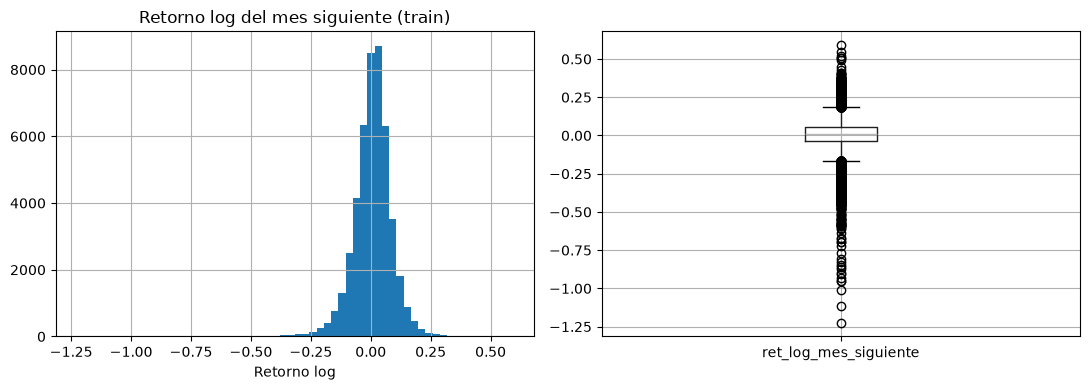

In [3]:
fig, ax = plt.subplots(1,2,figsize=(11,4)); train[TARGET].hist(bins=60,ax=ax[0]); ax[0].set_title('Retorno log del mes siguiente (train)'); ax[0].set_xlabel('Retorno log'); train.boxplot(column=TARGET,ax=ax[1]); plt.tight_layout(); plt.show()

{'outliers_IQR_pct': np.float64(3.83795763542599), 'outliers_z3_pct': np.float64(1.2722158291778545)}


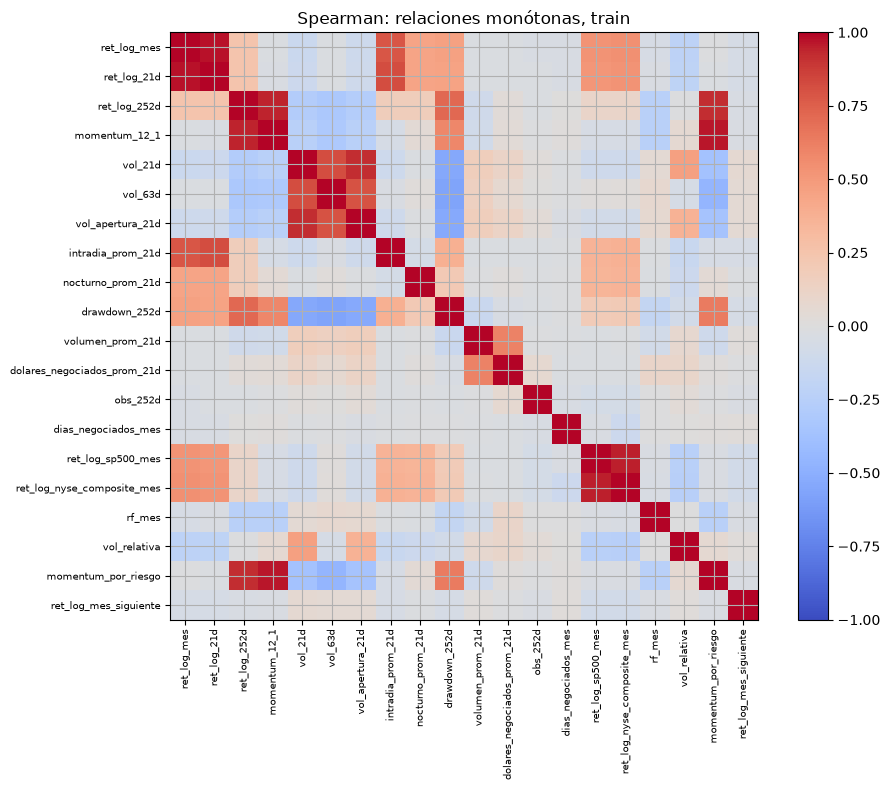

In [4]:
q1,q3=train[TARGET].quantile([.25,.75]); iqr=q3-q1; out_iqr=((train[TARGET]<q1-1.5*iqr)|(train[TARGET]>q3+1.5*iqr)).mean(); z=(train[TARGET]-train[TARGET].mean())/train[TARGET].std(); print({'outliers_IQR_pct':100*out_iqr,'outliers_z3_pct':100*z.abs().ge(3).mean()})
corr=train[FEATURES+[TARGET]].corr(method='spearman'); fig,ax=plt.subplots(figsize=(10,8)); im=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm'); ax.set_xticks(range(len(corr)),corr.columns,rotation=90,fontsize=7); ax.set_yticks(range(len(corr)),corr.columns,fontsize=7); fig.colorbar(im,ax=ax); ax.set_title('Spearman: relaciones monótonas, train'); plt.tight_layout(); plt.show()

Se usa Spearman para explorar relaciones monótonas con menor sensibilidad a magnitudes extremas. Esta exploración no elige modelos con el hold-out.

In [5]:
hallazgos=pd.DataFrame([{'hallazgo':'Colas del target','evidencia':f'{100*out_iqr:.2f}% fuera de IQR','consecuencia':'Comparar RMSE con MAE; no eliminar extremos automáticamente'}, {'hallazgo':'Escala de volatilidad variable','evidencia':f'vol_63d: p10={train.vol_63d.quantile(.1):.4f}, p90={train.vol_63d.quantile(.9):.4f}','consecuencia':'Probar momentum normalizado por riesgo'}, {'hallazgo':'Panel repetido por mes','evidencia':f'{train.anio_mes.nunique()} meses; {len(train)} observaciones','consecuencia':'CV por meses completos con purga, sin split aleatorio de filas'}]); display(hallazgos); hallazgos.to_csv(ROOT/'docs/hallazgos_eda.csv',index=False)

,hallazgo,evidencia,consecuencia
0,Colas del target,3.84% fuera de IQR,Comparar RMSE con MAE; no eliminar extremos au...
1,Escala de volatilidad variable,"vol_63d: p10=0.1484, p90=0.4131",Probar momentum normalizado por riesgo
2,Panel repetido por mes,158 meses; 46926 observaciones,"CV por meses completos con purga, sin split al..."
